<a href="https://colab.research.google.com/github/sbillel/L03-tree-stability/blob/main/tree_and_model_stability_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Eloise Mcdonough

**Date:** 11/16/26

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, export_text
from sklearn.linear_model import LinearRegression

df = pd.read_csv("heart_failure.csv")
print(df.shape)
print(df.isna().sum().sum(), "missing values,", df.duplicated().sum(), "duplicate rows")

df = df.drop(columns="time")


df["creatinine_phosphokinase"] = np.arcsinh(df["creatinine_phosphokinase"])
df["serum_creatinine"] = np.arcsinh(df["serum_creatinine"])

y = df["DEATH_EVENT"]
X = df.drop(columns="DEATH_EVENT")
features = list(X.columns)

(299, 13)
0 missing values, 0 duplicate rows


The data has 299 rows, with no missing values and no duplicate rows. I dropped time because it’s the follow up period, which is only known after the outcome happens so it leaks the answer. I also applied the IHS transform to creatinine_phosphokinase and serum_creatinine because both are very right skewed.

In [5]:
def fit_models(seed):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    tree = DecisionTreeRegressor(max_depth=3, random_state=0).fit(X_train, y_train)
    lm = LinearRegression().fit(X_train, y_train)
    return tree, lm, X_test, y_test

main_seed = 3001
tree0, lm0, X_test0, y_test0 = fit_models(main_seed)

tree_pred0 = tree0.predict(X_test0)
lm_pred0 = lm0.predict(X_test0)

print("Tree   test R^2:", round(tree0.score(X_test0, y_test0), 3),
      " accuracy:", round(np.mean((tree_pred0 > 0.5) == y_test0), 3))
print("Linear test R^2:", round(lm0.score(X_test0, y_test0), 3),
      " accuracy:", round(np.mean((lm_pred0 > 0.5) == y_test0), 3))
print(export_text(tree0, feature_names=features))

Tree   test R^2: 0.16  accuracy: 0.75
Linear test R^2: 0.199  accuracy: 0.783
|--- serum_creatinine <= 1.33
|   |--- ejection_fraction <= 27.50
|   |   |--- age <= 64.00
|   |   |   |--- value: [0.47]
|   |   |--- age >  64.00
|   |   |   |--- value: [0.79]
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.00
|   |   |   |--- value: [0.14]
|   |   |--- age >  79.00
|   |   |   |--- value: [0.71]
|--- serum_creatinine >  1.33
|   |--- serum_sodium <= 135.50
|   |   |--- creatinine_phosphokinase <= 7.11
|   |   |   |--- value: [0.88]
|   |   |--- creatinine_phosphokinase >  7.11
|   |   |   |--- value: [0.33]
|   |--- serum_sodium >  135.50
|   |   |--- serum_creatinine <= 1.53
|   |   |   |--- value: [1.00]
|   |   |--- serum_creatinine >  1.53
|   |   |   |--- value: [0.22]



With seed 3001, the tree gets a test R² of 0.16 and accuracy of 0.75. The linear model gets a test R² of 0.20 and accuracy of 0.78.

In [7]:
other_seeds = [1, 2, 3, 4]
coefs = pd.DataFrame({main_seed: lm0.coef_}, index=features)
tree_preds = pd.DataFrame({main_seed: tree_pred0})
lm_preds = pd.DataFrame({main_seed: lm_pred0})

for s in other_seeds:
    tree, lm, X_test, y_test = fit_models(s)
    print("Seed", s, " tree test R^2:", round(tree.score(X_test, y_test), 3),
          " linear test R^2:", round(lm.score(X_test, y_test), 3))
    print(export_text(tree, feature_names=features))
    coefs[s] = lm.coef_

    tree_preds[s] = tree.predict(X_test0)
    lm_preds[s] = lm.predict(X_test0)

print(coefs.round(4))

Seed 1  tree test R^2: 0.176  linear test R^2: 0.187
|--- serum_creatinine <= 1.17
|   |--- ejection_fraction <= 27.50
|   |   |--- serum_sodium <= 131.00
|   |   |   |--- value: [1.00]
|   |   |--- serum_sodium >  131.00
|   |   |   |--- value: [0.48]
|   |--- ejection_fraction >  27.50
|   |   |--- age <= 79.00
|   |   |   |--- value: [0.12]
|   |   |--- age >  79.00
|   |   |   |--- value: [0.67]
|--- serum_creatinine >  1.17
|   |--- serum_sodium <= 135.50
|   |   |--- age <= 44.50
|   |   |   |--- value: [0.00]
|   |   |--- age >  44.50
|   |   |   |--- value: [0.86]
|   |--- serum_sodium >  135.50
|   |   |--- ejection_fraction <= 61.00
|   |   |   |--- value: [0.37]
|   |   |--- ejection_fraction >  61.00
|   |   |   |--- value: [1.00]

Seed 2  tree test R^2: 0.163  linear test R^2: 0.237
|--- serum_creatinine <= 1.17
|   |--- ejection_fraction <= 27.50
|   |   |--- serum_sodium <= 132.00
|   |   |   |--- value: [1.00]
|   |   |--- serum_sodium >  132.00
|   |   |   |--- value: 

The seeds are 1, 2, 3 and 4. The trees look  different from each other. They all split first on serum_creatinine, but the cutoff moves between 1.17 and 1.36. Below that, the splits use different variables and CPK each show up in some trees. The linear coefficients are much more stable. serum_creatinine stays around 0.34–0.36, ejection_fraction around −0.009, age around 0.008 and serum_sodium around −0.01. Only the small binary variables move much, and diabetes even flips sign.

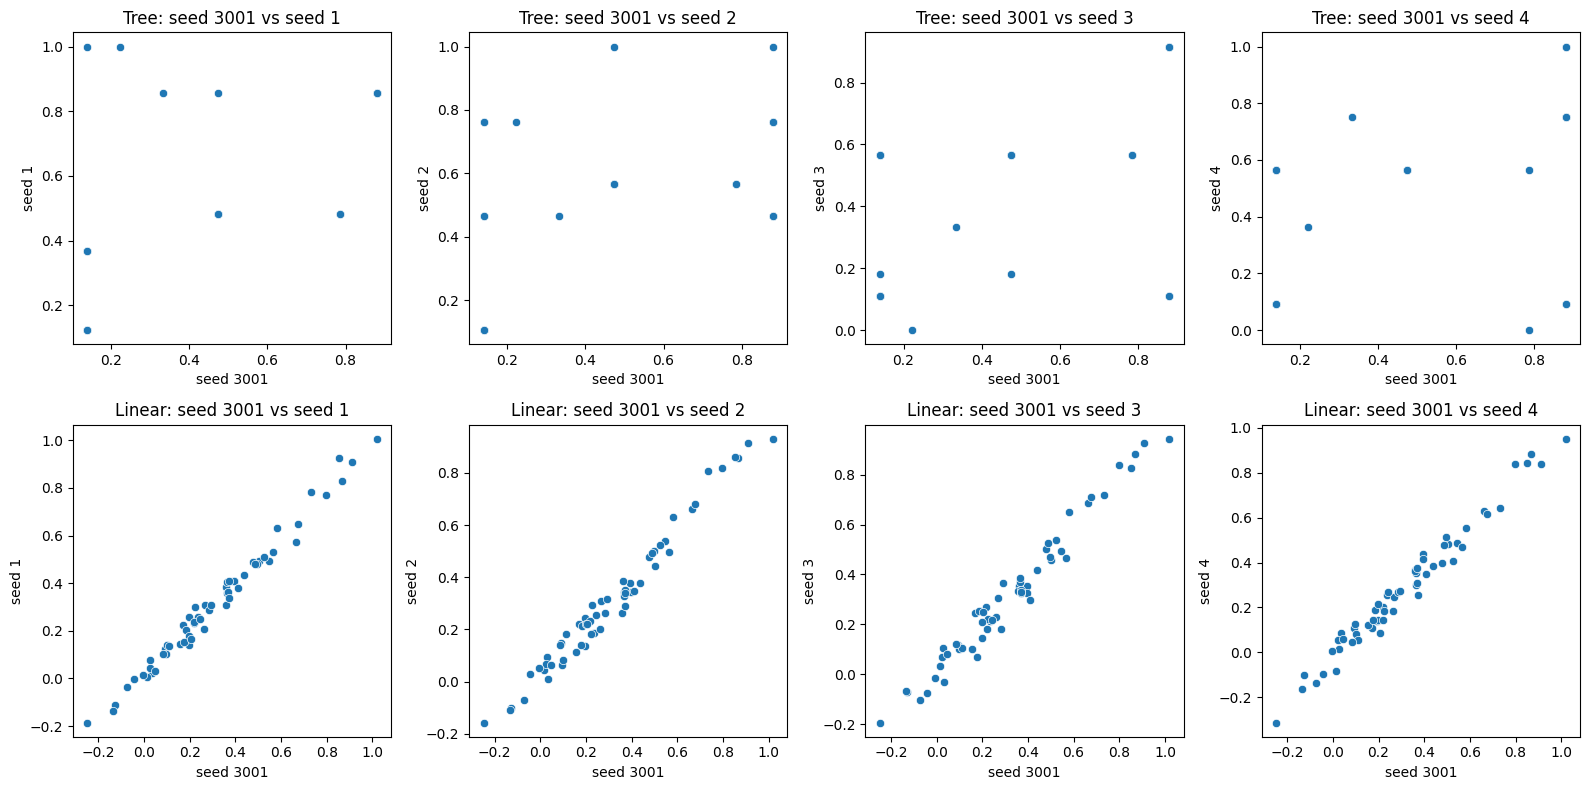

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for i, s in enumerate(other_seeds):
    sns.scatterplot(x=tree_preds[main_seed], y=tree_preds[s], ax=axes[0, i])
    axes[0, i].set(title=f"Tree: seed {main_seed} vs seed {s}", xlabel=f"seed {main_seed}", ylabel=f"seed {s}")
    sns.scatterplot(x=lm_preds[main_seed], y=lm_preds[s], ax=axes[1, i])
    axes[1, i].set(title=f"Linear: seed {main_seed} vs seed {s}", xlabel=f"seed {main_seed}", ylabel=f"seed {s}")
plt.tight_layout()
plt.show()

The linear model predictions fall almost exactly on a straight line, so they’re very similar. The tree predictions form a blocky, scattered cloud. They still trend upward, so they’re somewhat similar, but much less so than the linear models.

In [10]:
print(pd.DataFrame({"tree": tree_preds.corr()[main_seed][other_seeds],
                    "linear": lm_preds.corr()[main_seed][other_seeds]}).round(3))

    tree  linear
1  0.805   0.992
2  0.708   0.987
3  0.752   0.984
4  0.642   0.987


For the trees, the correlations are 0.64–0.81, which is moderate to fairly high. For the linear models, they’re 0.98–0.99, which is really high.

In [11]:
def slr(x, y):
    x_bar, y_bar = np.mean(x), np.mean(y)
    b1 = np.inner(x - x_bar, y - y_bar) / np.inner(x - x_bar, x - x_bar)
    b0 = y_bar - b1 * x_bar
    resid = y - (b0 + b1 * x)
    rsq = 1 - np.inner(resid, resid) / np.inner(y - y_bar, y - y_bar)
    return b0, b1, rsq

rows = []
for s in other_seeds:
    rows.append(["tree", s, *slr(tree_preds[main_seed], tree_preds[s])])
    rows.append(["linear", s, *slr(lm_preds[main_seed], lm_preds[s])])
print(pd.DataFrame(rows, columns=["model", "seed", "intercept", "slope", "R^2"]).round(3))

    model  seed  intercept  slope    R^2
0    tree     1      0.070  0.879  0.647
1  linear     1      0.017  0.963  0.984
2    tree     2      0.096  0.681  0.501
3  linear     2      0.019  0.942  0.973
4    tree     3      0.063  0.773  0.566
5  linear     3      0.009  0.962  0.968
6    tree     4      0.097  0.648  0.412
7  linear     4     -0.023  0.979  0.975


For the linear models, the intercept is close to  0, the slope is about 1 (0.94–0.98) and R² is about close to 1.  For the trees, the intercept is pretty close to 0. However, the slope is  below 1 and R squared is not close to 1

5. Yes the linear models have similar coefficients and nearly identical predictions across splits. The trees don’t, their structure changes a lot, and their predictions are related but only moderately similar.

6. This is mostly true for this dataset. The trees look different, but they all rely on the same signals. Because of that, their predictions are positively correlated and agree for most patients. They aren’t that similar, though. R² is only 0.4–0.65, because a small change in a split can move a patient into a different leaf. For the linear models the statement holds, since their coefficients and predictions dont really change.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]